In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["figure.dpi"] = 110

# Задача 1. Метод Монте-Карло и бросок монеты

Бросаем симметричную монету ($n = 100$) раз.

Какова вероятность того, что среди этих $100$ бросков найдётся хотя бы один подряд идущий прогон из $7$ и более орлов (то есть существует подряд идущая подпоследовательность длины ($\ge 7$), состоящая только из орлов)?  

**Почему нужен метод Монте-Карло?**

Формула для распределения максимальной длины подряд идущих орлов существует через рекуррентные/марковские методы, но получается громоздкая и неинтуитивная; аналитический вывод — трудоёмкий. Методом Монте-Карло проще оценить искомую вероятность.

**Алгоритм решения**

1. Моделируем эксперимент $N$ раз (каждый эксперимент = $100$ независимых бросков монеты).  
2. Если в очередном эксперименте получаем длину в $7$ подряд идущих орлов, то считаем этот эксперимент "удачным".
3. Находим долю "удачных" экспериментов. Это значение и будет веротяностью при нашей модели.
4. Составляем таблицу из столбцов ($N - p$), в каждую строчку которой заносим количество экспериментов и долю "удачных" экспериментов.

In [ ]:
from scipy.stats import norm
import random

In [ ]:
def estimate_p(N, n_flips=100, k=7):
    """Оценка вероятности, что в n_flips бросках будет серия >= k орлов"""
    success = 0
    for _ in range(N):
        max_run = 0
        current_run = 0
        i = 0
        while i < n_flips and max_run < k:   # условие выхода заранее
            f = random.choice([0, 1])
            if f == 1:
                current_run += 1
                if current_run > max_run:
                    max_run = current_run
            else:
                current_run = 0
            i += 1
        if max_run >= k:
            success += 1
    return success / N

Зададим разные значения N для проверки.

In [ ]:
N_values = [1000, 5000, 10000, 100000]

In [ ]:
results = []
for N in N_values:
    p_hat = estimate_p(N)
    results.append({"N": N, "p_hat": p_hat})

df = pd.DataFrame(results)
print(df)

        N    p_hat
0    1000  0.31900
1    5000  0.32220
2   10000  0.32200
3  100000  0.31883


**Вывод**

Видим, что доли "удачных" экспериментов тем ближе к истинным пропорциям, чем больше симуляций мы проводим. Истинный правильный ответ составляет $\approx0.31752$.

# Задача 2. Алерты для продуктовых метрик

Необходимо построить систему, основанную на квантилях или доверительных интервалах, которая будет выявлять алерты метрик, т.е. их пиковые или необычные значения.

Данные: **6300 сессий за 14 сентября — 4 октября 2026 года**, три полные недели.

Метрики:
 - `cr_like` — конверсия в лайк
 - `len_session` — средняя длительность сессии в секундах.


## Данные

Одна строка CSV — одна сессия.

По времени начала добавим день недели, номер часа и флаг выходного.

Из времени начала и окончания найдём длительность.


In [ ]:
raw = pd.read_csv('Data_for_Alerts.csv')

raw.head()

,id_session,start_session,end_session,flag_like
0,s000001,2026-09-14 00:13:20,2026-09-14 00:17:20,0
1,s000002,2026-09-14 00:20:59,2026-09-14 00:31:23,1
2,s000003,2026-09-14 00:22:33,2026-09-14 00:26:32,1
3,s000004,2026-09-14 00:23:28,2026-09-14 00:26:17,0
4,s000005,2026-09-14 00:32:37,2026-09-14 00:34:12,0


Произведем необходимые манипуляции с данными.

In [ ]:
raw['start_session'] = pd.to_datetime(raw['start_session'])
raw['end_session'] = pd.to_datetime(raw['end_session'])
raw = raw.sort_values('start_session').reset_index(drop=True)
raw['len_session'] = (raw['end_session'] - raw['start_session']).dt.total_seconds()
raw['ts_hour'] = raw['start_session'].dt.floor('h')
raw['date'] = raw['start_session'].dt.normalize()
raw['hour'] = raw['start_session'].dt.hour
raw['day_of_week'] = raw['start_session'].dt.dayofweek
raw['is_weekend'] = (raw['day_of_week'] >= 5).astype(int)
raw['week'] = (raw['date'] - raw['date'].min()).dt.days // 7 + 1

raw.head()


,id_session,start_session,end_session,flag_like,len_session,ts_hour,date,hour,day_of_week,is_weekend,week
0,s000001,2026-09-14 00:13:20,2026-09-14 00:17:20,0,240.0,2026-09-14,2026-09-14,0,0,0,1
1,s000002,2026-09-14 00:20:59,2026-09-14 00:31:23,1,624.0,2026-09-14,2026-09-14,0,0,0,1
2,s000003,2026-09-14 00:22:33,2026-09-14 00:26:32,1,239.0,2026-09-14,2026-09-14,0,0,0,1
3,s000004,2026-09-14 00:23:28,2026-09-14 00:26:17,0,169.0,2026-09-14,2026-09-14,0,0,0,1
4,s000005,2026-09-14 00:32:37,2026-09-14 00:34:12,0,95.0,2026-09-14,2026-09-14,0,0,0,1


Создадим переменную с квантилем нормального стандартного распределения.

In [ ]:
z = 1.96

Перейдём к группировке таблицы.

In [ ]:
df = raw.groupby('ts_hour').agg(
    sessions=('id_session', 'size'),
    cr_like=('flag_like', 'mean'),
    len_session=('len_session', 'mean')
).reset_index().rename(columns={'ts_hour': 'ts'})

In [ ]:
df['date'] = df['ts'].dt.normalize()
df['hour'] = df['ts'].dt.hour
df['day_of_week'] = df['ts'].dt.dayofweek
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

cr_ylim = (-0.03, 1.03)
len_ylim = (0, df['len_session'].max() * 1.1)

print('Сессий:', len(raw))
print('Почасовых точек:', len(df))
df.head()

Сессий: 6300
Почасовых точек: 504


,ts,sessions,cr_like,len_session,date,hour,day_of_week,is_weekend
0,2026-09-14 00:00:00,7,0.428571,788.285714,2026-09-14,0,0,0
1,2026-09-14 01:00:00,6,0.500000,692.166667,2026-09-14,1,0,0
2,2026-09-14 02:00:00,8,0.125000,1148.125000,2026-09-14,2,0,0
3,2026-09-14 03:00:00,8,0.375000,767.750000,2026-09-14,3,0,0
4,2026-09-14 04:00:00,9,0.444444,1007.111111,2026-09-14,4,0,0


## Общая визуализация метрик


In [ ]:
import matplotlib.dates as mdates

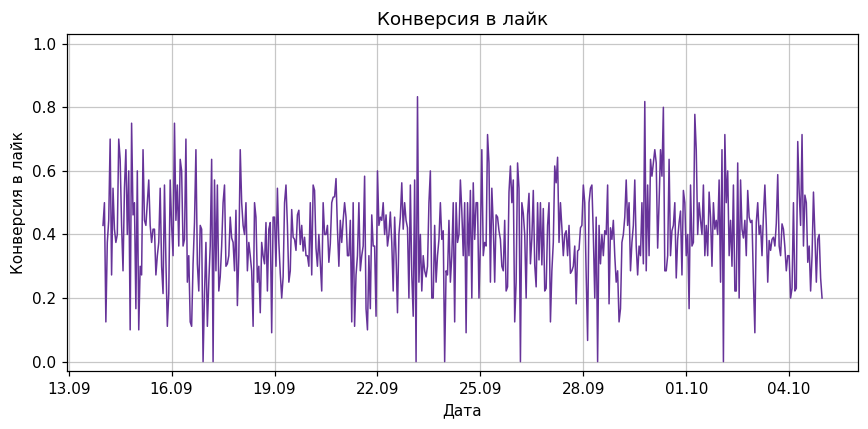

In [ ]:
plt.figure()
plt.plot(df['ts'], df['cr_like'], color='rebeccapurple', lw=1)
plt.title('Конверсия в лайк')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.grid(alpha=0.7)
plt.tight_layout()
plt.show()


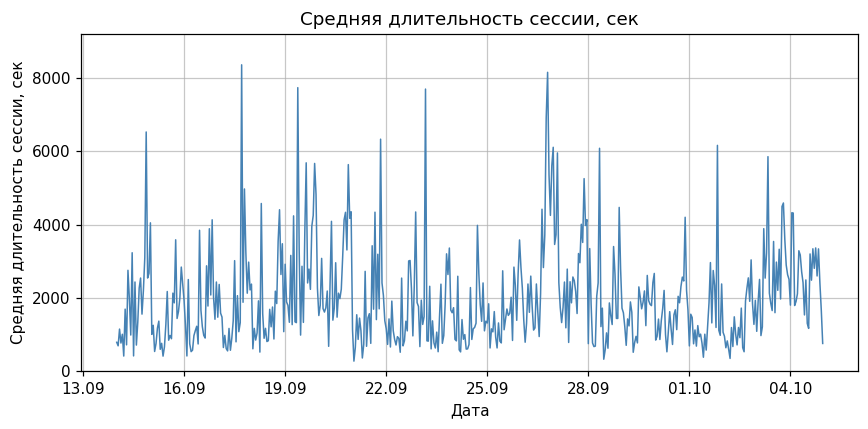

In [ ]:
plt.figure()
plt.plot(df['ts'], df['len_session'], color='steelblue', lw=1)
plt.title('Средняя длительность сессии, сек')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, сек')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.grid(alpha=0.7)
plt.tight_layout()
plt.show()


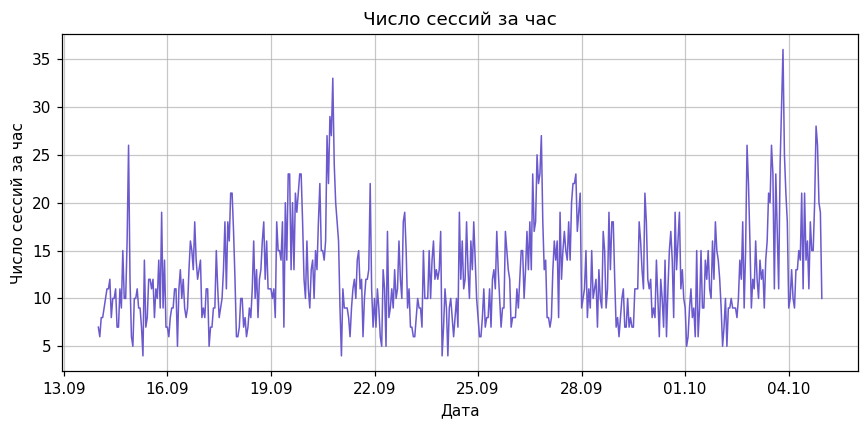

In [ ]:
plt.figure()
plt.plot(df['ts'], df['sessions'], color='slateblue', lw=1)
plt.title('Число сессий за час')
plt.xlabel('Дата')
plt.ylabel('Число сессий за час')

plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.grid(alpha=0.7)
plt.tight_layout()
plt.show()


Сравним метрики на выходных и на будних.

In [ ]:
daily = raw.groupby(['date', 'is_weekend']).agg(
    sessions=('id_session', 'size'),
    cr_like=('flag_like', 'mean'),
    len_session=('len_session', 'mean')
).reset_index()

print('Среднее число сессий в день:')
print(daily.groupby('is_weekend')['sessions'].mean().round(1))
print('Средняя длительность сессии:')
print(raw.groupby('is_weekend')['len_session'].mean().round(1))
print('Конверсия по неделям:')
print(raw.groupby('week')['flag_like'].mean().round(3))


Среднее число сессий в день:
is_weekend
0    262.9
1    392.8
Name: sessions, dtype: float64
Средняя длительность сессии:
is_weekend
0    1763.1
1    2942.7
Name: len_session, dtype: float64
Конверсия по неделям:
week
1    0.391
2    0.383
3    0.408
Name: flag_like, dtype: float64


Видим, что и количество сессий и их длительность выше на выходных, чем в будни.

## Доверительный интервал и система алертов

Приближённый $95\%$-й ДИ среднего:

$$
\overline x\pm1.96\frac{\sigma}{\sqrt n}.
$$

 - Для конверсии $\overline x$ — среднее флагов $0/1$, а $n$ — число сессий.
 - Для длительности сессии $n$ также означает число сессий, а не число точек на графике.

Попробуем построить три типа доверительных интервалов:
 - Общий (основанный на всех данных, вне зависимости от часа и дня);
 - Сегментированный по дню недели (для каждого дня недели свой расчёт);
 - Сегментированный по часу суток + флагу выходного дня;

Для каждого типа доверительных интервалов построим два варианта:
 - Основанный на всех данных из таблицы;
 - Кумулятивный только на тех данных, которые доступны к моменты расчёта;




### ДИ по всем сессиям

Сначала одна пара границ для всей истории.


Определим первую точку.

In [ ]:
m_len = raw['len_session'].mean()
m_cr = raw['flag_like'].mean()

s_len = raw['len_session'].std()
s_cr = raw['flag_like'].std()
n_all = len(raw)

print("Средняя длительность сессии = ", m_len)
print("Средняя длительность конверсии = ", m_cr)
print()
print("Стандотклон длительности сессии = ", s_len)
print("Стандотклон конверсии = ", s_cr)
print()
print("Кол-во наблюдений = ", n_all)

Средняя длительность сессии =  2204.454761904762
Средняя длительность конверсии =  0.3942857142857143

Стандотклон длительности сессии =  4356.622816525643
Стандотклон конверсии =  0.48873551586034575

Кол-во наблюдений =  6300


In [ ]:
len_half = z * s_len / np.sqrt(n_all)
cr_half = z * s_cr / np.sqrt(n_all)

print(len_half)
print(cr_half)

107.58104493394187
0.01206867789727916


In [ ]:
len_low_all = np.full(len(df), raw['len_session'].mean() - len_half)
len_up_all = np.full(len(df), raw['len_session'].mean() + len_half)
print(len_low_all[:1])
print(len_up_all[:1])

cr_low_all = np.full(len(df), raw['flag_like'].mean() - cr_half)
cr_up_all = np.full(len(df), raw['flag_like'].mean() + cr_half)
print(cr_low_all[:1])
print(cr_up_all[:1])

[2096.87371697]
[2312.03580684]
[0.38221704]
[0.40635439]


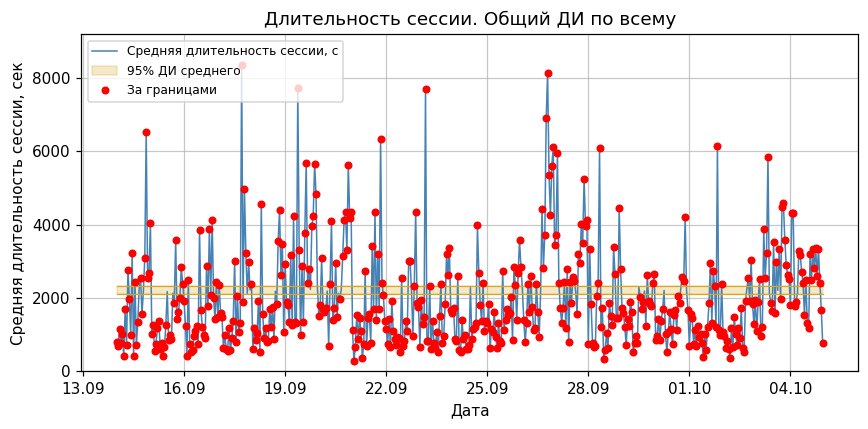

Точек за границами: 478 из 504


In [ ]:
lower = len_low_all
upper = len_up_all
values = df['len_session'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='steelblue', lw=1, label='Средняя длительность сессии, с')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='95% ДИ среднего')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Длительность сессии. Общий ДИ по всему')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, сек')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.7)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


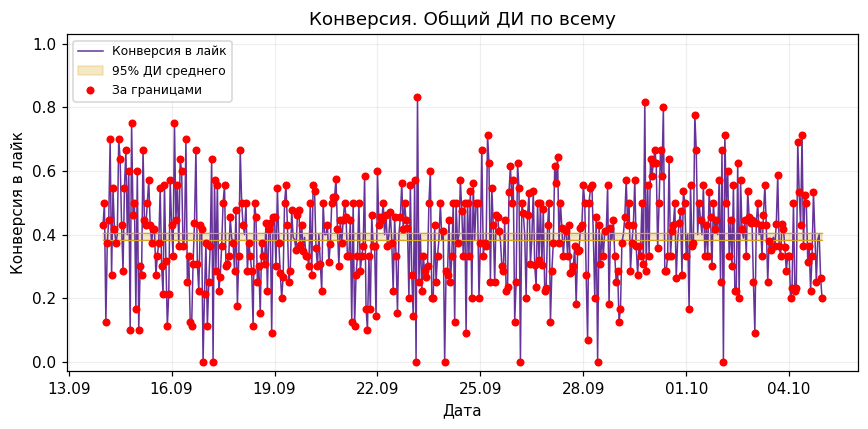

Точек за границами: 464 из 504


In [ ]:
lower = cr_low_all
upper = cr_up_all
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='95% ДИ среднего')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Общий ДИ по всему')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


In [ ]:
tmp = raw.assign(
    len_sq=raw['len_session'] ** 2
)

by_date = tmp.groupby('date').agg(
    n=('id_session', 'size'),
    len_sum=('len_session', 'sum'),
    len_sq_sum=('len_sq', 'sum'),
    like_sum=('flag_like', 'sum')
).sort_index()

# Кумулятивные суммы
by_date['n_cum'] = by_date['n'].cumsum()
by_date['len_sum_cum'] = by_date['len_sum'].cumsum()
by_date['len_sq_sum_cum'] = by_date['len_sq_sum'].cumsum()
by_date['like_sum_cum'] = by_date['like_sum'].cumsum()

# Кумулятивные средние
by_date['len_mean'] = (by_date['len_sum_cum'] / by_date['n_cum'])
by_date['cr_mean'] = (by_date['like_sum_cum'] / by_date['n_cum'])

# Кумулятивные выборочные дисперсии
by_date['len_var'] = (by_date['len_sq_sum_cum'] - by_date['len_sum_cum'] ** 2 / by_date['n_cum']) / (by_date['n_cum'] - 1)
by_date['cr_var'] = (by_date['like_sum_cum'] - by_date['like_sum_cum'] ** 2 / by_date['n_cum']) / (by_date['n_cum'] - 1)

# Кумулятивные стандартные отклонения
by_date['s_len'] = np.sqrt(by_date['len_var'].clip(lower=0))
by_date['s_cr'] = np.sqrt(by_date['cr_var'].clip(lower=0))

# ДИ
by_date['len_half'] = (z * by_date['s_len'] / np.sqrt(by_date['n_cum']))
by_date['cr_half'] = (z * by_date['s_cr'] / np.sqrt(by_date['n_cum']))

cum_all = df[['date']].merge(by_date.reset_index(), on='date', how='left')

len_low_cum = (cum_all['len_mean'] - cum_all['len_half']).to_numpy()
len_up_cum = (cum_all['len_mean'] + cum_all['len_half']).to_numpy()
cr_low_cum = (cum_all['cr_mean'] - cum_all['cr_half']).to_numpy()
cr_up_cum = (cum_all['cr_mean'] + cum_all['cr_half']).to_numpy()

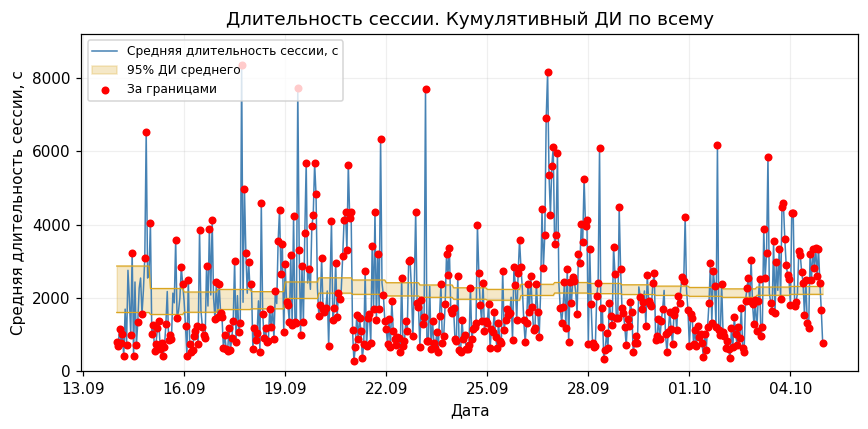

Точек за границами: 455 из 504


In [ ]:
lower = len_low_cum
upper = len_up_cum
values = df['len_session'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='steelblue', lw=1, label='Средняя длительность сессии, с')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='95% ДИ среднего')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Длительность сессии. Кумулятивный ДИ по всему')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, с')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


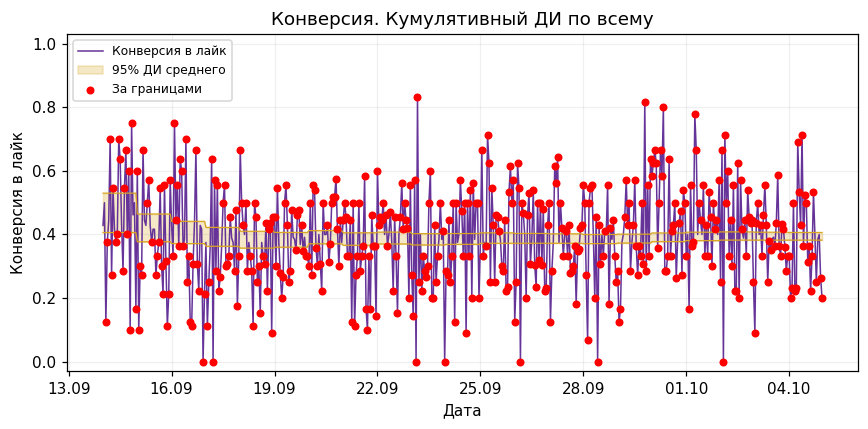

Точек за границами: 433 из 504


In [ ]:
lower = cr_low_cum
upper = cr_up_cum
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='95% ДИ среднего')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Кумулятивный ДИ по всему')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


In [ ]:
by_date[['n_cum', 'len_half', 'cr_half']].round(4).head(8)

,n_cum,len_half,cr_half
date,,,
2026-09-14,250,632.9719,0.0620
2026-09-15,492,353.9940,0.0437
2026-09-16,758,275.8399,0.0350
2026-09-17,1042,273.6815,0.0297
2026-09-18,1293,234.1598,0.0265
2026-09-19,1683,224.9335,0.0232
2026-09-20,2110,208.6793,0.0208
2026-09-21,2362,195.2435,0.0196


In [ ]:
by_date[['n_cum', 'len_half', 'cr_half']].round(4).tail()

,n_cum,len_half,cr_half
date,,,
2026-09-30,4959,125.8262,0.0136
2026-10-01,5222,120.7836,0.0133
2026-10-02,5496,115.7603,0.0129
2026-10-03,5929,111.8953,0.0124
2026-10-04,6300,107.5810,0.0121


Заметно, что при увеличении количества данных длина доверительного интервала уменьшается.

При том это происходит угасающими темпами, так как кол-во наблюдений и длина интервала находятся в обратной зависимости вида $1 / \sqrt{n}$.

### ДИ по дням недели

Теперь повторим те же действия, но доверительный интервал будет рассчитываться для каждого дня недели по отдельности.

Также построим общий вариант и кумулятивный.


In [ ]:
stats_day = raw.groupby('day_of_week').agg(
    n=('id_session', 'size'),
    len_mean=('len_session', 'mean'),
    cr_mean=('flag_like', 'mean'),
    s_len=('len_session', 'std'),
    s_cr=('flag_like', 'std')
)

stats_day['len_half'] = (z * stats_day['s_len'] / np.sqrt(stats_day['n']))
stats_day['cr_half'] = (z * stats_day['s_cr'] / np.sqrt(stats_day['n']))

full_day = df[['day_of_week']].merge(stats_day.reset_index(), on='day_of_week', how='left')

len_low_day = (full_day['len_mean'] - full_day['len_half']).to_numpy()
len_up_day = (full_day['len_mean'] + full_day['len_half']).to_numpy()
cr_low_day = (full_day['cr_mean'] - full_day['cr_half']).to_numpy()
cr_up_day = (full_day['cr_mean'] + full_day['cr_half']).to_numpy()

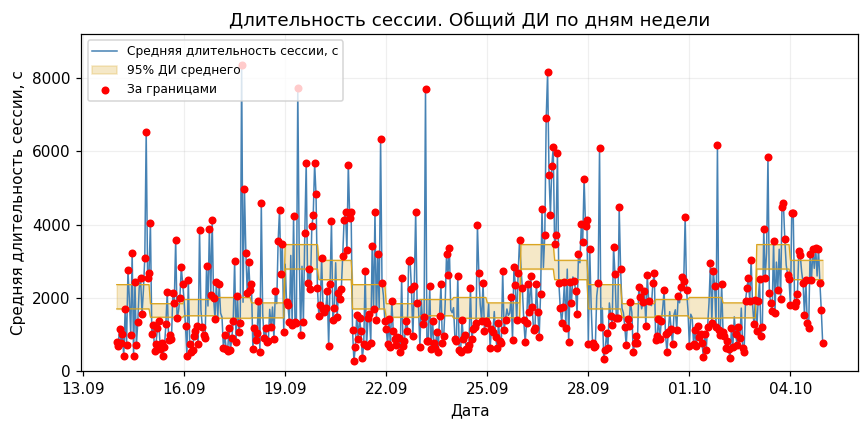

Точек за границами: 436 из 504


In [ ]:
lower = len_low_day
upper = len_up_day
values = df['len_session'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='steelblue', lw=1, label='Средняя длительность сессии, с')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='95% ДИ среднего')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Длительность сессии. Общий ДИ по дням недели')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, с')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


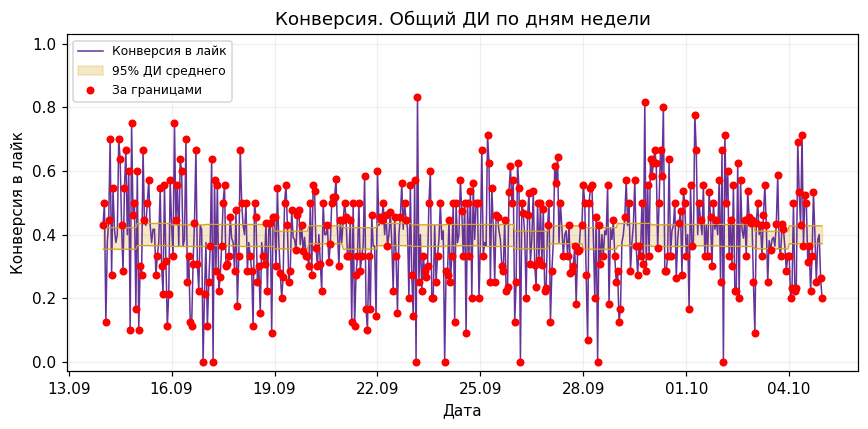

Точек за границами: 404 из 504


In [ ]:
lower = cr_low_day
upper = cr_up_day
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='95% ДИ среднего')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Общий ДИ по дням недели')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


In [ ]:
tmp = raw.assign(len_sq=raw['len_session'] ** 2)

daily_day = tmp.groupby(['date', 'day_of_week']).agg(
    n=('id_session', 'size'),
    len_sum=('len_session', 'sum'),
    len_sq_sum=('len_sq', 'sum'),
    like_sum=('flag_like', 'sum')
).reset_index().sort_values('date')

g = daily_day.groupby('day_of_week')

daily_day['n_cum'] = g['n'].cumsum()
daily_day['len_sum_cum'] = g['len_sum'].cumsum()
daily_day['len_sq_sum_cum'] = g['len_sq_sum'].cumsum()
daily_day['like_sum_cum'] = g['like_sum'].cumsum()

daily_day['len_mean'] = (daily_day['len_sum_cum'] / daily_day['n_cum'])
daily_day['cr_mean'] = (daily_day['like_sum_cum'] / daily_day['n_cum'])

daily_day['len_var'] = (daily_day['len_sq_sum_cum'] - daily_day['len_sum_cum'] ** 2 / daily_day['n_cum']) / (daily_day['n_cum'] - 1)
daily_day['cr_var'] = (daily_day['like_sum_cum'] - daily_day['like_sum_cum'] ** 2 / daily_day['n_cum']) / (daily_day['n_cum'] - 1)

daily_day['s_len'] = np.sqrt(daily_day['len_var'].clip(lower=0))
daily_day['s_cr'] = np.sqrt(daily_day['cr_var'].clip(lower=0))

daily_day['len_half'] = (z * daily_day['s_len'] / np.sqrt(daily_day['n_cum']))
daily_day['cr_half'] = (z * daily_day['s_cr'] / np.sqrt(daily_day['n_cum']))

cum_day = df[['date', 'day_of_week']].merge(daily_day, on=['date', 'day_of_week'], how='left')

len_low_day_cum = (cum_day['len_mean'] - cum_day['len_half']).to_numpy()
len_up_day_cum = (cum_day['len_mean'] + cum_day['len_half']).to_numpy()

cr_low_day_cum = (cum_day['cr_mean'] - cum_day['cr_half']).to_numpy()
cr_up_day_cum = (cum_day['cr_mean'] + cum_day['cr_half']).to_numpy()

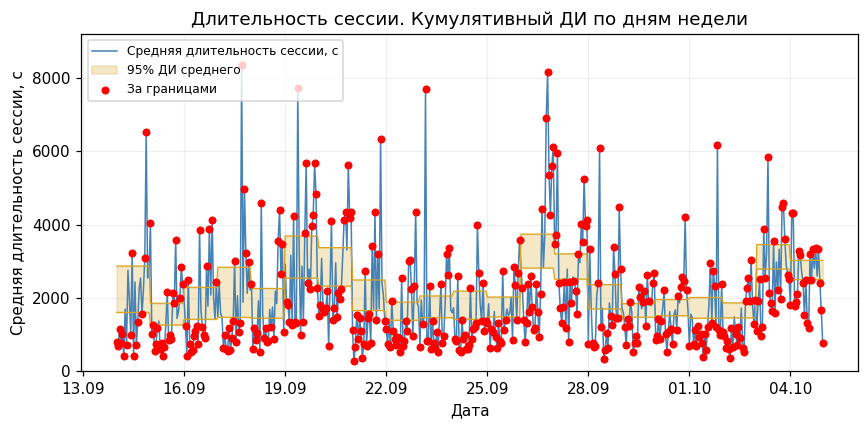

Точек за границами: 405 из 504


In [ ]:
lower = len_low_day_cum
upper = len_up_day_cum
values = df['len_session'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='steelblue', lw=1, label='Средняя длительность сессии, с')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='95% ДИ среднего')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Длительность сессии. Кумулятивный ДИ по дням недели')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, с')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


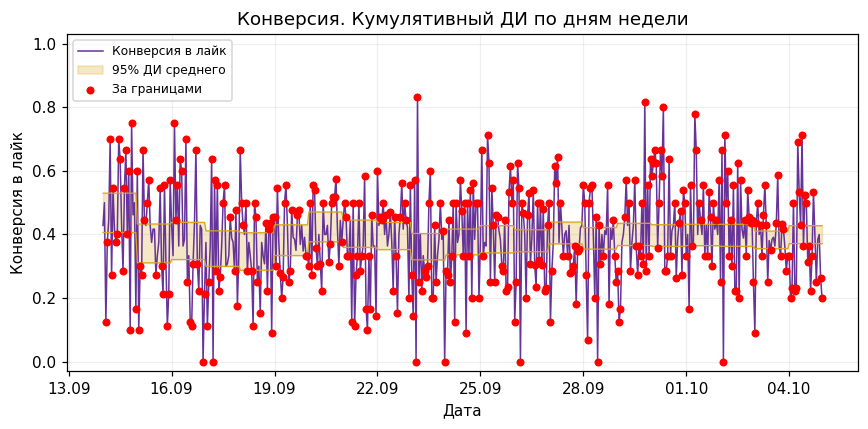

Точек за границами: 380 из 504


In [ ]:
lower = cr_low_day_cum
upper = cr_up_day_cum
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='95% ДИ среднего')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Кумулятивный ДИ по дням недели')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


**Вопрос**

Почему в недельных доверительных интервалах получается меньше выбросов?

**Ответ**

Потому что там меньше распределений.

### ДИ по флагу выходного и часу

Сегмент для расчёта доверительного интервала задаётся флагом выходного и номером часа. Например, для будних 18:00 используем все сессии будних дней, начавшиеся в 18-й час.


In [ ]:
stats_cell = raw.groupby(
    ['is_weekend', 'hour']
).agg(
    n=('id_session', 'size'),
    len_mean=('len_session', 'mean'),
    cr_mean=('flag_like', 'mean'),
    s_len=('len_session', 'std'),
    s_cr=('flag_like', 'std')
)

stats_cell['len_half'] = (z * stats_cell['s_len'] / np.sqrt(stats_cell['n']))
stats_cell['cr_half'] = (z * stats_cell['s_cr'] / np.sqrt(stats_cell['n']))

full_cell = df[['is_weekend', 'hour']].merge(stats_cell.reset_index(), on=['is_weekend', 'hour'], how='left')

len_low_cell = (full_cell['len_mean'] - full_cell['len_half']).to_numpy()
len_up_cell = (full_cell['len_mean'] + full_cell['len_half']).to_numpy()
cr_low_cell = (full_cell['cr_mean'] - full_cell['cr_half']).to_numpy()
cr_up_cell = (full_cell['cr_mean'] + full_cell['cr_half']).to_numpy()

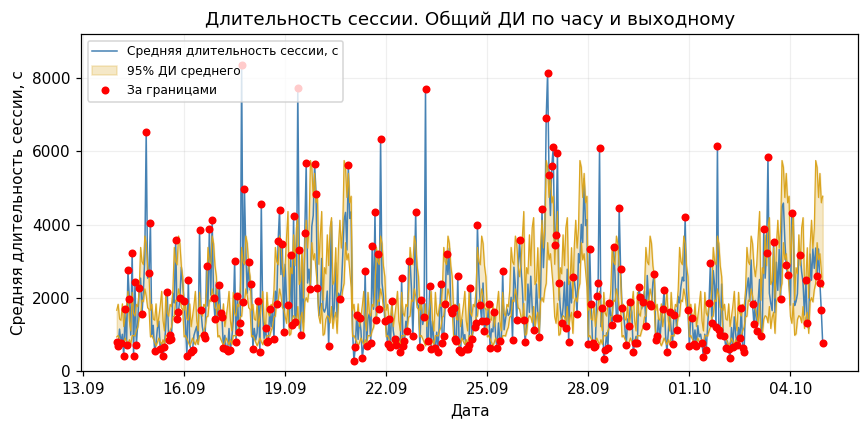

Точек за границами: 270 из 504


In [ ]:
lower = len_low_cell
upper = len_up_cell
values = df['len_session'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='steelblue', lw=1, label='Средняя длительность сессии, с')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='95% ДИ среднего')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Длительность сессии. Общий ДИ по часу и выходному')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, с')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


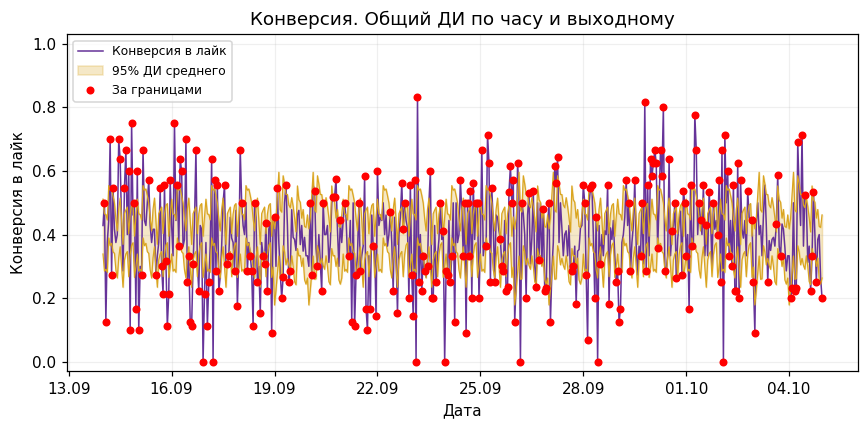

Точек за границами: 268 из 504


In [ ]:
lower = cr_low_cell
upper = cr_up_cell
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='95% ДИ среднего')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Общий ДИ по часу и выходному')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


In [ ]:
tmp = raw.assign(len_sq=raw['len_session'] ** 2)

daily_cell = tmp.groupby(
    ['date', 'is_weekend', 'hour']
).agg(
    n=('id_session', 'size'),
    len_sum=('len_session', 'sum'),
    len_sq_sum=('len_sq', 'sum'),
    like_sum=('flag_like', 'sum')
).reset_index().sort_values('date')

g = daily_cell.groupby(['is_weekend', 'hour'])

daily_cell['n_cum'] = g['n'].cumsum()
daily_cell['len_sum_cum'] = g['len_sum'].cumsum()
daily_cell['len_sq_sum_cum'] = g['len_sq_sum'].cumsum()
daily_cell['like_sum_cum'] = g['like_sum'].cumsum()

daily_cell['len_mean'] = (daily_cell['len_sum_cum'] / daily_cell['n_cum'])
daily_cell['cr_mean'] = (daily_cell['like_sum_cum'] / daily_cell['n_cum'])

daily_cell['len_var'] = (daily_cell['len_sq_sum_cum'] - daily_cell['len_sum_cum'] ** 2 / daily_cell['n_cum']) / (daily_cell['n_cum'] - 1)
daily_cell['cr_var'] = (daily_cell['like_sum_cum'] - daily_cell['like_sum_cum'] ** 2 / daily_cell['n_cum']) / (daily_cell['n_cum'] - 1)

daily_cell['s_len'] = np.sqrt(daily_cell['len_var'].clip(lower=0))
daily_cell['s_cr'] = np.sqrt(daily_cell['cr_var'].clip(lower=0))
daily_cell['len_half'] = (z * daily_cell['s_len'] / np.sqrt(daily_cell['n_cum']))
daily_cell['cr_half'] = (z * daily_cell['s_cr'] / np.sqrt(daily_cell['n_cum']))

cum_cell = df[['date', 'is_weekend', 'hour']].merge(daily_cell, on=['date', 'is_weekend', 'hour'], how='left')

len_low_cell_cum = (cum_cell['len_mean'] - cum_cell['len_half']).to_numpy()
len_up_cell_cum = (cum_cell['len_mean'] + cum_cell['len_half']).to_numpy()
cr_low_cell_cum = (cum_cell['cr_mean'] - cum_cell['cr_half']).to_numpy()
cr_up_cell_cum = (cum_cell['cr_mean'] + cum_cell['cr_half']).to_numpy()

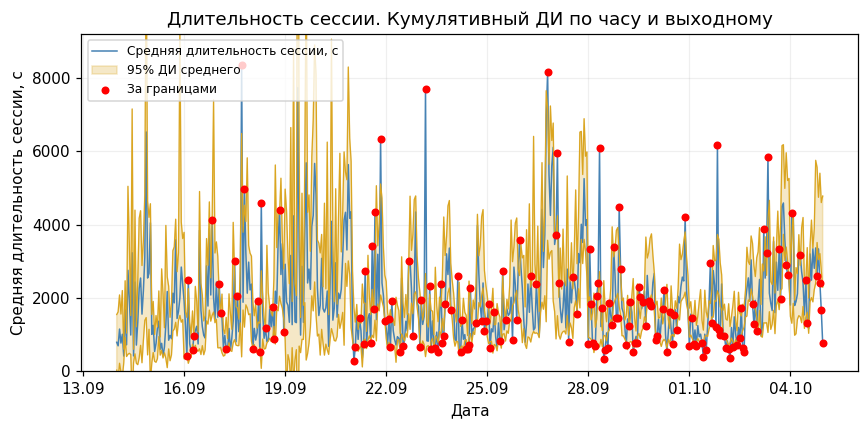

Точек за границами: 163 из 504


In [ ]:
lower = len_low_cell_cum
upper = len_up_cell_cum
values = df['len_session'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='steelblue', lw=1, label='Средняя длительность сессии, с')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='95% ДИ среднего')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Длительность сессии. Кумулятивный ДИ по часу и выходному')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, с')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


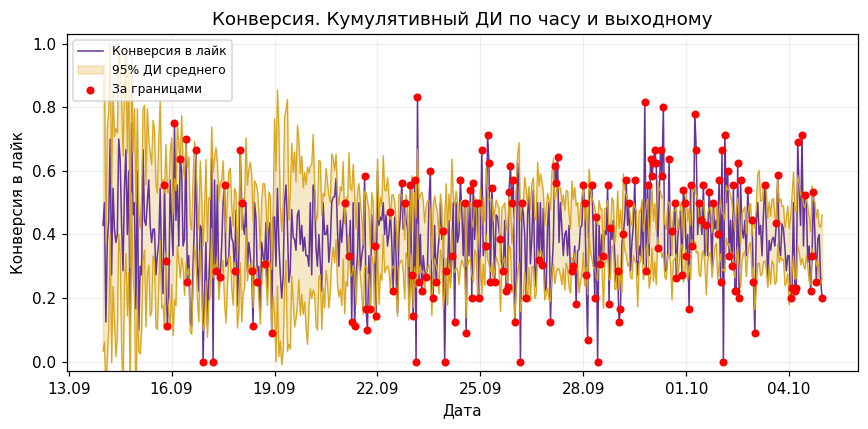

Точек за границами: 174 из 504


In [ ]:
lower = cr_low_cell_cum
upper = cr_up_cell_cum
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='95% ДИ среднего')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Кумулятивный ДИ по часу и выходному')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


### Почему ДИ не подходит для таких алертов

ДИ показывает неопределённость оценки **математического ожидания**, а не диапазон обычных значений метрики во времени. Чем больше сессий в истории, тем меньше стандартная ошибка $\sigma/\sqrt n$ и тем уже ДИ. При этом сами почасовые метрики продолжают колебаться.

Поэтому выход почасовой метрики за ДИ общего среднего не означает, что возникла неполадка. Сегментация учитывает контекст, но не меняет смысл доверительного интервала.


## Квантили метрики длительности

Возьмём границы $q_{0.025}$ и $q_{0.975}$ **почасовых средних длительностей**. Так единица наблюдения для квантилей совпадает с точками на графике.

В общей версии используем всю историю, в накопительной — текущую и предыдущие точки. Для сегментов накопление идёт только внутри соответствующего сегмента. Это эмпирический диапазон колебаний метрики, а не доверительный интервал среднего.


### Квантили длительности по всем данным


In [ ]:
df.head(3)

,ts,sessions,cr_like,len_session,date,hour,day_of_week,is_weekend
0,2026-09-14 00:00:00,7,0.428571,788.285714,2026-09-14,0,0,0
1,2026-09-14 01:00:00,6,0.500000,692.166667,2026-09-14,1,0,0
2,2026-09-14 02:00:00,8,0.125000,1148.125000,2026-09-14,2,0,0


In [ ]:
q_len_session_all_low = np.full(len(df), df['len_session'].quantile(0.025))
q_len_session_all_up = np.full(len(df), df['len_session'].quantile(0.975))

print(q_len_session_all_low[:3])
print(q_len_session_all_up[:3])

[527.565 527.565 527.565]
[5673.0725 5673.0725 5673.0725]


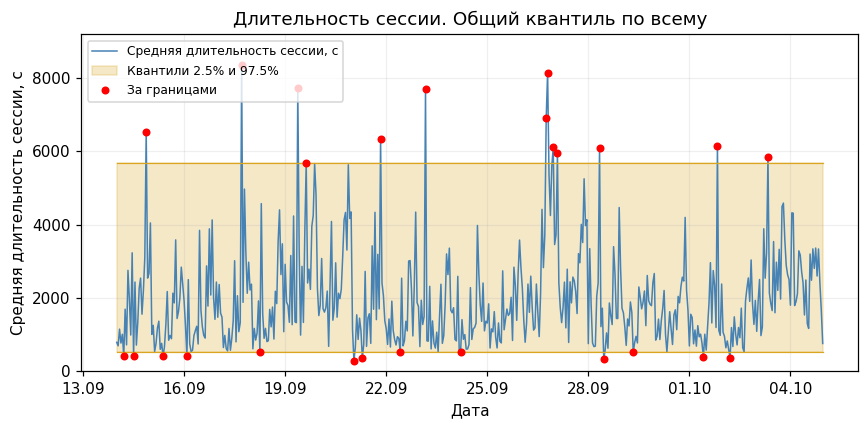

Точек за границами: 26 из 504


In [ ]:
lower = q_len_session_all_low
upper = q_len_session_all_up
values = df['len_session'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='steelblue', lw=1, label='Средняя длительность сессии, с')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Длительность сессии. Общий квантиль по всему')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, с')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


In [ ]:
q_len_session_all_low_series = df['len_session'].expanding().quantile(0.025)
q_len_session_all_up_series = df['len_session'].expanding().quantile(0.975)

q_len_session_all_low_cum = q_len_session_all_low_series.to_numpy()
q_len_session_all_up_cum = q_len_session_all_up_series.to_numpy()

print(q_len_session_all_low_series[:3])
print(q_len_session_all_up_series[:3])

0    788.285714
1    694.569643
2    696.972619
Name: len_session, dtype: float64
0     788.285714
1     785.882738
2    1130.133036
Name: len_session, dtype: float64


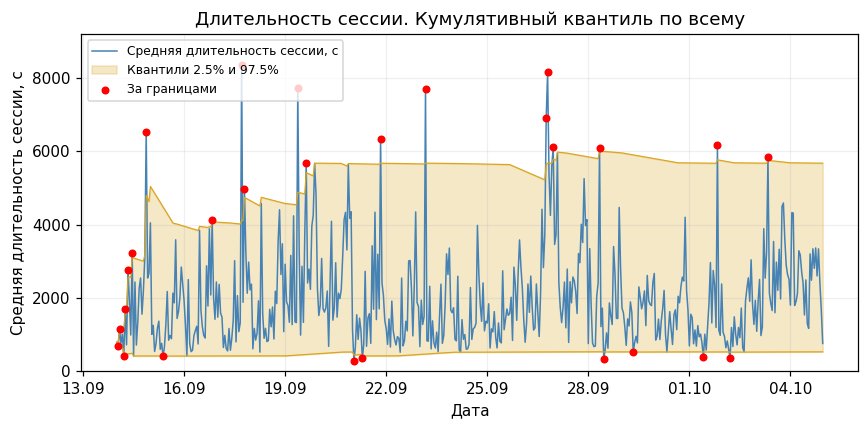

Точек за границами: 27 из 504


In [ ]:
lower = q_len_session_all_low_cum
upper = q_len_session_all_up_cum
values = df['len_session'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='steelblue', lw=1, label='Средняя длительность сессии, с')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Длительность сессии. Кумулятивный квантиль по всему')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, с')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


### Квантили длительности по дням недели


In [ ]:
q_len_session_day_stats = pd.DataFrame({
    'lower': df.groupby(['day_of_week'])['len_session'].quantile(0.025),
    'upper': df.groupby(['day_of_week'])['len_session'].quantile(0.975)
}).reset_index()
q_len_session_day_full = df[['day_of_week']].merge(q_len_session_day_stats, on=['day_of_week'], how='left')
q_len_session_day_low = q_len_session_day_full['lower'].to_numpy()
q_len_session_day_up = q_len_session_day_full['upper'].to_numpy()

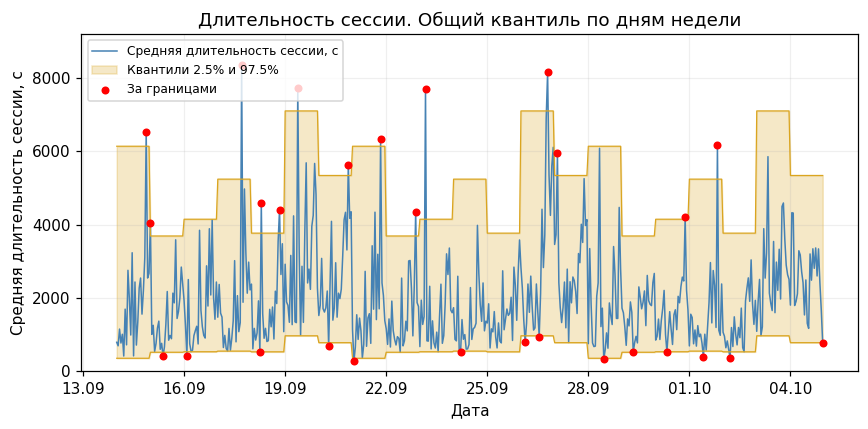

Точек за границами: 28 из 504


In [ ]:
lower = q_len_session_day_low
upper = q_len_session_day_up
values = df['len_session'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='steelblue', lw=1, label='Средняя длительность сессии, с')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Длительность сессии. Общий квантиль по дням недели')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, с')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


In [ ]:
q_len_session_day_low_series = (
    df.groupby(['day_of_week'])['len_session'].expanding().quantile(0.025)
    .reset_index(level=[0], drop=True).sort_index()
)
q_len_session_day_up_series = (
    df.groupby(['day_of_week'])['len_session'].expanding().quantile(0.975)
    .reset_index(level=[0], drop=True).sort_index()
)


In [ ]:
q_len_session_day_low_cum = q_len_session_day_low_series.to_numpy()
q_len_session_day_up_cum = q_len_session_day_up_series.to_numpy()


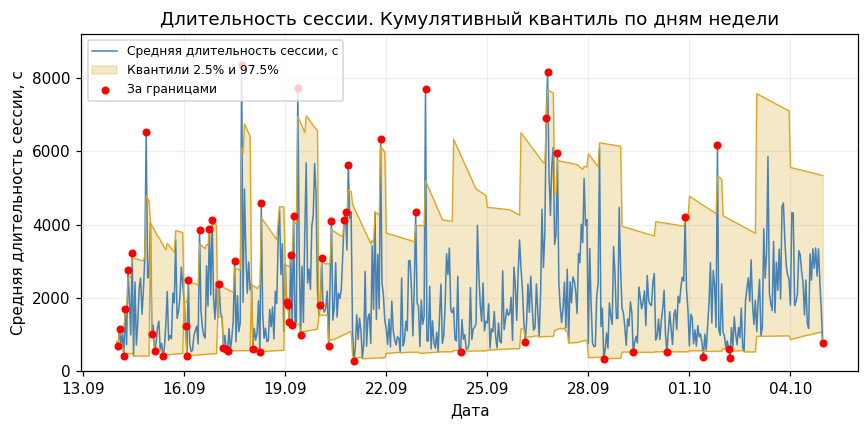

Точек за границами: 58 из 504


In [ ]:
lower = q_len_session_day_low_cum
upper = q_len_session_day_up_cum
values = df['len_session'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='steelblue', lw=1, label='Средняя длительность сессии, с')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Длительность сессии. Кумулятивный квантиль по дням недели')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, с')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


### Квантили длительности по флагу выходного и часу


In [ ]:
q_len_session_cell_stats = pd.DataFrame({
    'lower': df.groupby(['is_weekend', 'hour'])['len_session'].quantile(0.025),
    'upper': df.groupby(['is_weekend', 'hour'])['len_session'].quantile(0.975)
}).reset_index()
q_len_session_cell_full = df[['is_weekend', 'hour']].merge(q_len_session_cell_stats, on=['is_weekend', 'hour'], how='left')
q_len_session_cell_low = q_len_session_cell_full['lower'].to_numpy()
q_len_session_cell_up = q_len_session_cell_full['upper'].to_numpy()


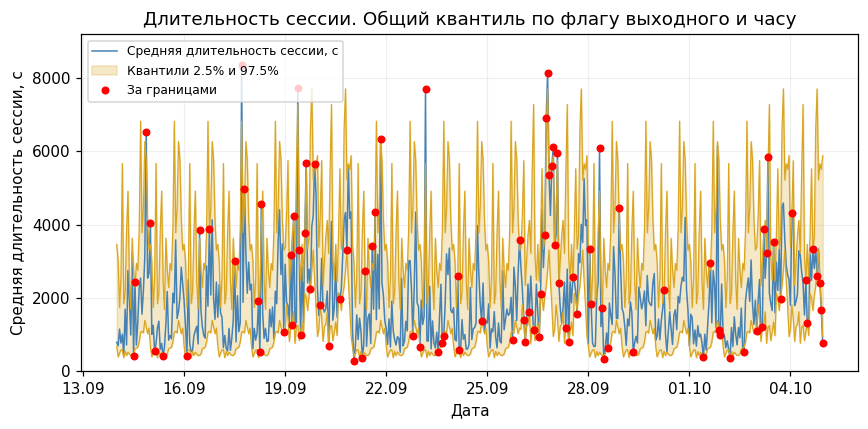

Точек за границами: 96 из 504


In [ ]:
lower = q_len_session_cell_low
upper = q_len_session_cell_up
values = df['len_session'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='steelblue', lw=1, label='Средняя длительность сессии, с')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Длительность сессии. Общий квантиль по флагу выходного и часу')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, с')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


In [ ]:
q_len_session_cell_low_series = (
    df.groupby(['is_weekend', 'hour'])['len_session'].expanding().quantile(0.025)
    .reset_index(level=[0, 1], drop=True).sort_index()
)
q_len_session_cell_up_series = (
    df.groupby(['is_weekend', 'hour'])['len_session'].expanding().quantile(0.975)
    .reset_index(level=[0, 1], drop=True).sort_index()
)


In [ ]:
q_len_session_cell_low_cum = q_len_session_cell_low_series.to_numpy()
q_len_session_cell_up_cum = q_len_session_cell_up_series.to_numpy()


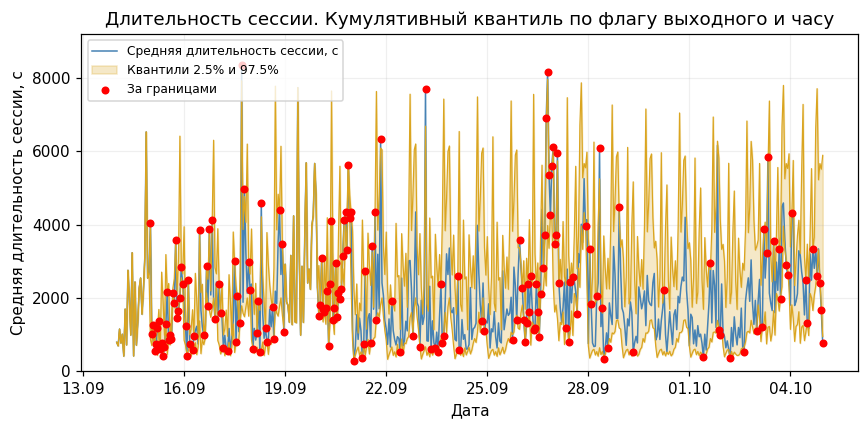

Точек за границами: 177 из 504


In [ ]:
lower = q_len_session_cell_low_cum
upper = q_len_session_cell_up_cum
values = df['len_session'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='steelblue', lw=1, label='Средняя длительность сессии, с')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Длительность сессии. Кумулятивный квантиль по флагу выходного и часу')
plt.xlabel('Дата')
plt.ylabel('Средняя длительность сессии, с')
plt.ylim(len_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


## Квантили отдельных флагов лайка

Сначала возьмём квантили исходных нулей и единиц. При конверсии около $0.4$ границы всей истории получаются **0 и 1**. Между ними лежит любая возможная конверсия, поэтому такие границы неинформативны.


### Квантили отдельных флагов по всем данным


In [ ]:
q_flag_like_all_low = np.full(len(df), raw['flag_like'].quantile(0.025))
q_flag_like_all_up = np.full(len(df), raw['flag_like'].quantile(0.975))

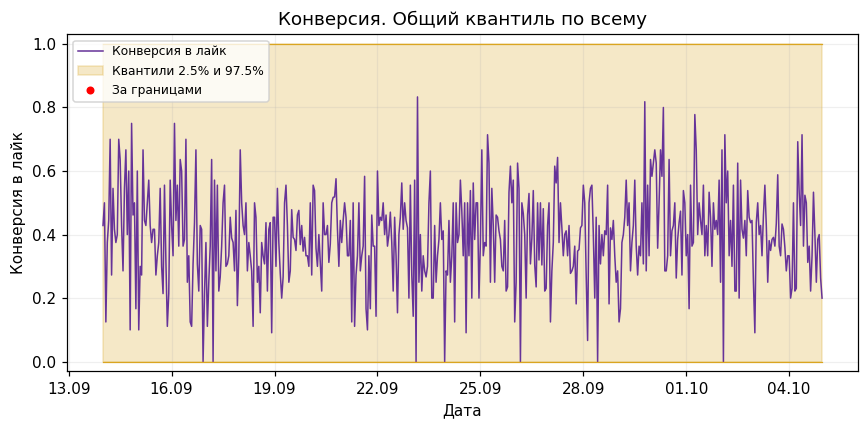

Точек за границами: 0 из 504


In [ ]:
lower = q_flag_like_all_low
upper = q_flag_like_all_up
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Общий квантиль по всему')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


**Вывод**

Для бинарных значений этот подход не работает, так как верхняя и нижняя граница могут принимать только значения $0$ и $1$.

## Квантили конверсий, рассчитанных по дням и часам

Теперь используем не отдельные флаги, а доли лайков: **отдельную конверсию за каждый час каждого календарного дня**.

Именно эти значения уже находятся в `df['cr_like']` и показаны на всех графиках конверсии.

То есть вместо сырых данных мы будем использовать агрегированные данные.


### Квантили конверсии по всем данным


In [ ]:
q_cr_like_all_low = np.full(len(df), df['cr_like'].quantile(0.025))
q_cr_like_all_up = np.full(len(df), df['cr_like'].quantile(0.975))

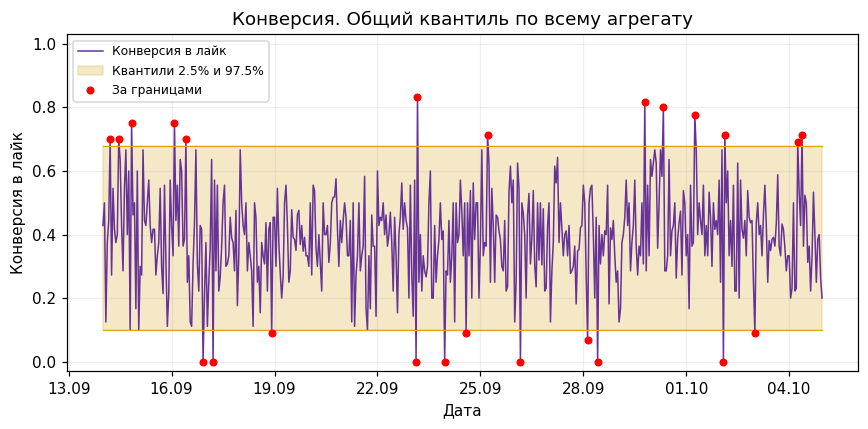

Точек за границами: 24 из 504


In [ ]:
lower = q_cr_like_all_low
upper = q_cr_like_all_up
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Общий квантиль по всему агрегату')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


In [ ]:
q_cr_like_all_low_series = df['cr_like'].expanding().quantile(0.025)
q_cr_like_all_up_series = df['cr_like'].expanding().quantile(0.975)

In [ ]:
q_cr_like_all_low_cum = q_cr_like_all_low_series.to_numpy()
q_cr_like_all_up_cum = q_cr_like_all_up_series.to_numpy()


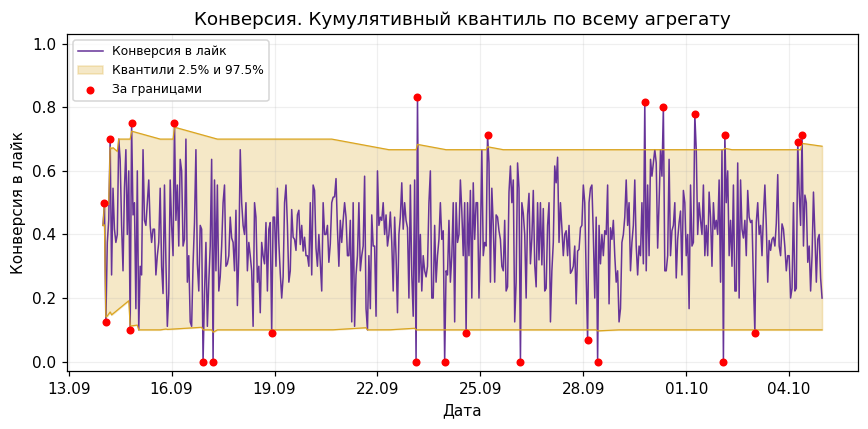

Точек за границами: 25 из 504


In [ ]:
lower = q_cr_like_all_low_cum
upper = q_cr_like_all_up_cum
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Кумулятивный квантиль по всему агрегату')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


### Квантили конверсии по дням недели


In [ ]:
q_cr_like_day_stats = pd.DataFrame({
    'lower': df.groupby(['day_of_week'])['cr_like'].quantile(0.025),
    'upper': df.groupby(['day_of_week'])['cr_like'].quantile(0.975)
}).reset_index()
q_cr_like_day_full = df[['day_of_week']].merge(q_cr_like_day_stats, on=['day_of_week'], how='left')
q_cr_like_day_low = q_cr_like_day_full['lower'].to_numpy()
q_cr_like_day_up = q_cr_like_day_full['upper'].to_numpy()


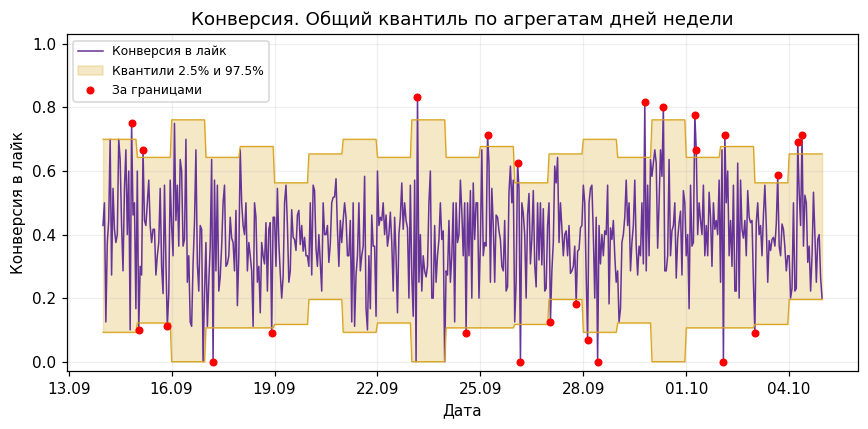

Точек за границами: 25 из 504


In [ ]:
lower = q_cr_like_day_low
upper = q_cr_like_day_up
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Общий квантиль по агрегатам дней недели')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


In [ ]:
q_cr_like_day_low_series = (
    df.groupby(['day_of_week'])['cr_like'].expanding().quantile(0.025)
    .reset_index(level=[0], drop=True).sort_index()
)
q_cr_like_day_up_series = (
    df.groupby(['day_of_week'])['cr_like'].expanding().quantile(0.975)
    .reset_index(level=[0], drop=True).sort_index()
)


In [ ]:
q_cr_like_day_low_cum = q_cr_like_day_low_series.to_numpy()
q_cr_like_day_up_cum = q_cr_like_day_up_series.to_numpy()

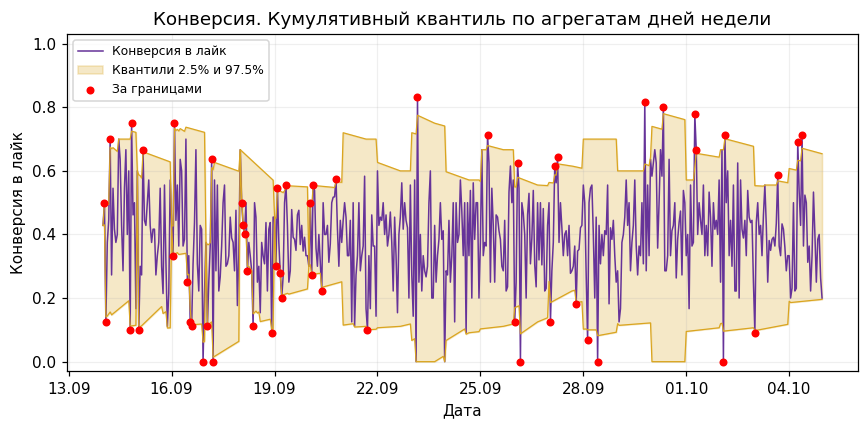

Точек за границами: 54 из 504


In [ ]:
lower = q_cr_like_day_low_cum
upper = q_cr_like_day_up_cum
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Кумулятивный квантиль по агрегатам дней недели')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


### Квантили конверсии по флагу выходного и часу


In [ ]:
q_cr_like_cell_stats = pd.DataFrame({
    'lower': df.groupby(['is_weekend', 'hour'])['cr_like'].quantile(0.025),
    'upper': df.groupby(['is_weekend', 'hour'])['cr_like'].quantile(0.975)
}).reset_index()
q_cr_like_cell_full = df[['is_weekend', 'hour']].merge(q_cr_like_cell_stats, on=['is_weekend', 'hour'], how='left')
q_cr_like_cell_low = q_cr_like_cell_full['lower'].to_numpy()
q_cr_like_cell_up = q_cr_like_cell_full['upper'].to_numpy()


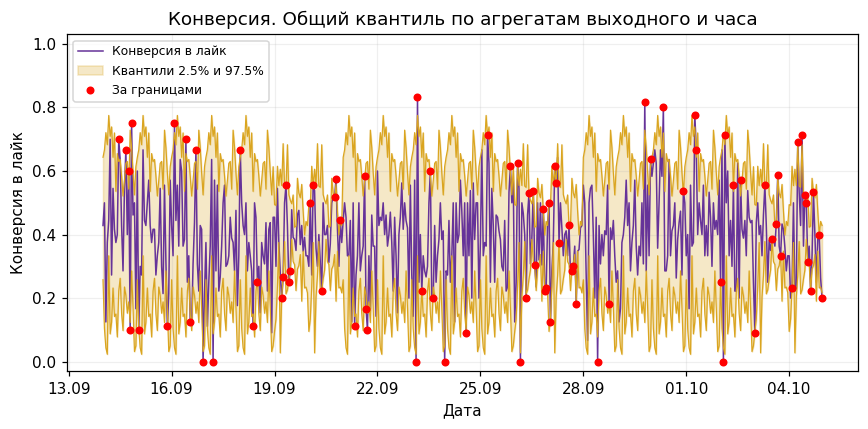

Точек за границами: 87 из 504


In [ ]:
lower = q_cr_like_cell_low
upper = q_cr_like_cell_up
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Общий квантиль по агрегатам выходного и часа')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


In [ ]:
q_cr_like_cell_low_series = (
    df.groupby(['is_weekend', 'hour'])['cr_like'].expanding().quantile(0.025)
    .reset_index(level=[0, 1], drop=True).sort_index()
)
q_cr_like_cell_up_series = (
    df.groupby(['is_weekend', 'hour'])['cr_like'].expanding().quantile(0.975)
    .reset_index(level=[0, 1], drop=True).sort_index()
)


In [ ]:
q_cr_like_cell_low_cum = q_cr_like_cell_low_series.to_numpy()
q_cr_like_cell_up_cum = q_cr_like_cell_up_series.to_numpy()


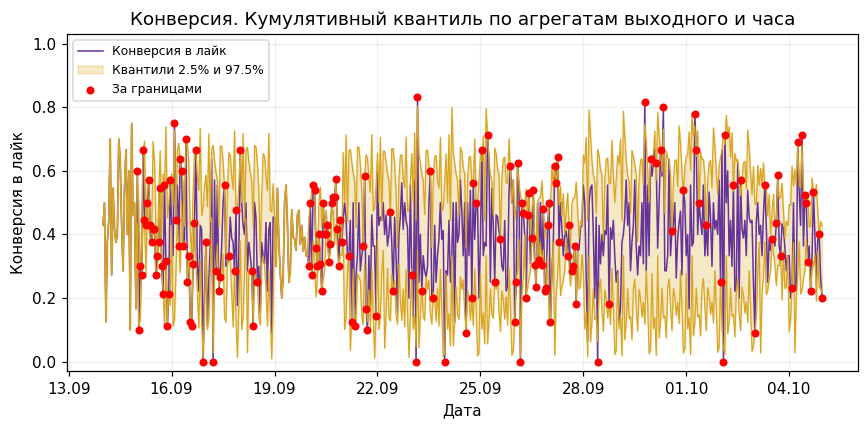

Точек за границами: 167 из 504


In [ ]:
lower = q_cr_like_cell_low_cum
upper = q_cr_like_cell_up_cum
values = df['cr_like'].to_numpy()
outliers = (values < lower) | (values > upper)

plt.figure()
plt.plot(df['ts'], values, color='rebeccapurple', lw=1, label='Конверсия в лайк')
plt.fill_between(df['ts'], lower, upper, color='goldenrod', alpha=0.25, label='Квантили 2.5% и 97.5%')
plt.plot(df['ts'], lower, color='goldenrod', lw=0.8)
plt.plot(df['ts'], upper, color='goldenrod', lw=0.8)
plt.scatter(df.loc[outliers, 'ts'], values[outliers], color='red', s=18, zorder=3, label='За границами')
plt.title('Конверсия. Кумулятивный квантиль по агрегатам выходного и часа')
plt.xlabel('Дата')
plt.ylabel('Конверсия в лайк')
plt.ylim(cr_ylim)
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.legend(loc='upper left', fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Точек за границами:', outliers.sum(), 'из', len(df))


## Вывод

1. ДИ среднего сужается при накоплении сессий и не описывает естественные колебания почасовой метрики. Использовать его как диапазон допустимых значений для таких алертов неправильно.
2. Квантили самой метрики описывают её наблюдаемый разброс. Разбиение по дню недели и по комбинации «выходной × час» учитывает контекст.
3. Для конверсии квантили отдельных флагов 0/1 дают неинформативные границы [0, 1]. Нужны квантили агрегированных долей с той же единицей наблюдения, что и на графике.
4. Квантили по небольшой истории нестабильны. Выход за границы — повод проверить метрику, а не доказательство неполадки.


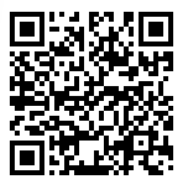